In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
n = 300
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
eta_special = 0
n_special = 1
t_transient = 200
tmax = 1200

In [3]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [ ]:
import csv
import os
import numpy as np
import torch
import random

seed = 0

filename = ".csv"

# Intestazioni delle colonne
header = [
    "seed", "sim_seed", "n_special", "beta", "delta",
    "pop",
    "pod",
    "rew_mean",
    "lastr_mean"
]

# Se il file non esiste, scrivi l'header
if not os.path.exists(filename):
    with open(filename, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(header)

for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):

        beta_special = beta
        delta_special = delta
        env = Ants_move_special( n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        beta_special, delta_special, tmax, n_special, t_transient)  
        
        sim_seed = i*len(delta_list) + j
        np.random.seed(sim_seed)
        random.seed(sim_seed)

        env.reset_objects()
        env.transient()

        rewards = []

        while env.t < tmax:
            env.update()
            new_state = env.get_state()
            rewards.append([env.get_reward(new_state, k) for k in range(env.n_special)])

        pop = env.order_parameter_s()
        pod = env.order_parameter_p()
        rew = np.mean(rewards)
        lastr = np.mean(np.array(rewards)[-50:])

        # Scriviamo direttamente nel CSV
        row_data = [
            seed, sim_seed, n_special, env.beta[-1], env.delta[-1],
            pop,  # std non calcolato singolo episodio
            pod,
            rew,
            lastr
        ]

        with open(filename, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow(row_data)

print(f"Risultati salvati per seed {seed}")


Risultati salvati per seed 0


In [5]:
# load the dataset
import pandas as pd
load = True
if load:
    dfbm = pd.read_csv("abm_ants_alone_bd.csv")

In [6]:
dfbm

,seed,sim_seed,n_special,beta,delta,pop,pod,rew_mean,lastr_mean
0,0,0,1,3.5,0.3,0.170217,0.273333,-1.196978,-1.161802
1,0,1,1,3.5,0.4,0.164611,0.266667,-1.211533,-1.174181
2,0,2,1,3.5,0.5,0.167115,0.086667,-1.208874,-1.087082
3,0,3,1,3.5,0.6,0.163817,0.253333,-1.243592,-1.266518
4,0,4,1,3.5,0.7,0.162555,0.180000,-1.267147,-1.260435
5,0,5,1,3.5,0.8,0.170725,0.160000,-1.207497,-1.240277
6,0,6,1,4.5,0.3,0.187761,0.286667,-1.258387,-1.185913
7,0,7,1,4.5,0.4,0.185611,0.173333,-1.204837,-1.189886
8,0,8,1,4.5,0.5,0.172942,0.266667,-1.205937,-1.197164
9,0,9,1,4.5,0.6,0.179647,0.193333,-1.180200,-1.249628


In [7]:
# average over n_special with standard deviation and skip the seeds column
df=dfbm.groupby(['n_special']).agg(['mean', 'std']).drop(columns=['seed', 'sim_seed','beta', 'delta'])

In [8]:
df.style.format("{:.2f}")

In [ ]:
raw_mean_df = dfbm.groupby(['n_special', 'beta', 'delta']).lastr_mean.mean().unstack().unstack()
std_mean_df = dfbm.groupby(['n_special', 'beta', 'delta']).lastr_mean.std().unstack().unstack()

raw_mean_df30 = raw_mean_df.loc[1]
std_mean_df30 = std_mean_df.loc[1]

raw_mean_arr30 = np.array(raw_mean_df30.values).reshape(len(delta_list), len(beta_list))
std_mean_arr30 = np.array(std_mean_df30.values).reshape(len(delta_list), len(beta_list))

KeyError: 30

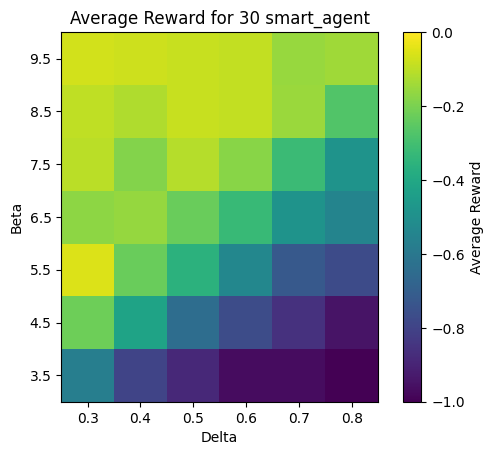

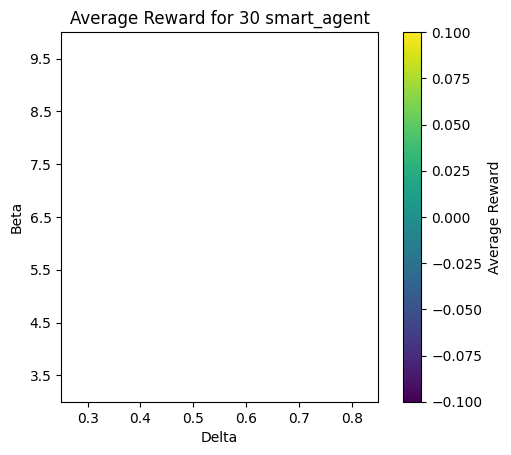

In [19]:
import matplotlib.pyplot as plt

plt.imshow(raw_mean_arr30.T, cmap='viridis', origin='lower', vmin=-1, vmax=0)
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title('Average Reward for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

plt.imshow(std_mean_arr30.T, cmap='viridis', origin='lower')
plt.colorbar(label='Average Reward')
plt.xlabel('Delta')
plt.ylabel('Beta')
plt.title('Average Reward for 30 smart_agent')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()